# Sparsity is the whole premise

Compressed sensing rests on one empirical fact: **natural signals are not
random**. They are sparse, or at least *compressible*, in some transform
basis $\boldsymbol{\Psi}$, even when they look dense in the measurement
domain. JPEG is the everyday proof: it throws away most of the DCT
coefficients of an image and nobody notices. This notebook makes that claim
measurable, first for a 1-D signal and then for a real photograph.

**In this notebook you will**

* build a two-tone signal that is dense in time but exactly 2-sparse in the
  discrete cosine transform (DCT);
* keep only the largest 1%, 5% and 20% of the DCT coefficients of a portrait
  and measure the reconstruction error and PSNR;
* compare how fast the sorted DCT magnitudes of the image and of white noise
  decay, which is what "compressible" means in practice.

**Before this notebook:** nothing; this is the first notebook of the module.
**Next:** `cs_illustrations` (the measurement model
$\boldsymbol{y}=\mathbf{C}\boldsymbol{\Psi}\boldsymbol{s}$ drawn as matrix
pictures).

**Runtime:** a few seconds on a laptop.

### Notation

* $\boldsymbol{x}\in\mathbb{R}^n$: the signal (samples or pixels), $n$ entries.
* $\boldsymbol{\Psi}\in\mathbb{R}^{n\times n}$: an orthonormal basis (here the
  inverse DCT), whose columns are the basis functions.
* $\boldsymbol{s}\in\mathbb{R}^n$: the coefficients of $\boldsymbol{x}$ in that
  basis, so that

$$\boldsymbol{x} = \boldsymbol{\Psi}\boldsymbol{s},\qquad
  \|\boldsymbol{s}\|_0 = k \ll n .$$

* $\|\boldsymbol{s}\|_0$: the number of nonzero entries of $\boldsymbol{s}$.
  A signal is $k$-sparse when $k$ of its coefficients are nonzero, and
  *compressible* when a few coefficients are large and the rest are small
  but not exactly zero.

The uncomfortable question this sets up: if we are going to discard 99% of
the coefficients anyway, **why did we measure all $n$ samples in the first
place?**

### Setup

Imports, the course plotting style, and the output folder for figures.
`save_dual` writes each figure twice (a light and a dark version). The
random generator `rng` is only used later to draw a white-noise image for
comparison.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct, idct, dctn, idctn
from pyutils import set_plot_style, save_dual, fg, muted
set_plot_style()

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
rng = np.random.default_rng(0)

## 1. A two-tone signal: dense in time, 2-sparse in frequency

The signal $x(t)=\cos(2\pi f_1 t)+\cos(2\pi f_2 t)$ has $n$ nonzero samples
and exactly two nonzero DCT coefficients. Sampling on the half-grid
$t_j=(j+\tfrac12)T/n$ aligns the cosines with the DCT-II basis functions
$\cos\!\big(\pi(j+\tfrac12)k/n\big)$, so the sparsity is exact rather than
approximate: frequency $f$ sits at index $k=2fT$.

Symbols in the cell below:

* $n$ = `N1D` = 1024 samples over a window of length $T$ = `T` = 1 s;
* $f_1$ = `F1` = 97 Hz and $f_2$ = `F2` = 337 Hz, the two tones;
* $\boldsymbol{x}$ = `x1d`, the sampled signal; $\boldsymbol{s}$ = `s1d`, its
  orthonormal DCT, so $\boldsymbol{x}=\boldsymbol{\Psi}\boldsymbol{s}$ with
  $\boldsymbol{\Psi}$ the inverse DCT;
* `nnz`: the number of DCT coefficients larger than $10^{-8}$ times the
  largest one (anything smaller is floating-point round-off).

The asserts check that exactly two coefficients are nonzero and that they
sit at the predicted indices $k_1=2f_1T$ and $k_2=2f_2T$. The last lines
compare the grid with the Nyquist rate $2f_{\max}$, the classical minimum
sampling rate for a signal whose highest frequency is $f_{\max}$.

In [2]:
N1D, T = 1024, 1.0
F1, F2 = 97.0, 337.0                       # Hz
t = (np.arange(N1D) + 0.5) * T / N1D
x1d = np.cos(2*np.pi*F1*t) + np.cos(2*np.pi*F2*t)
s1d = dct(x1d, norm='ortho')            # s = Psi^T x (orthonormal DCT-II)

k1, k2 = int(round(2*F1*T)), int(round(2*F2*T))   # predicted DCT indices k = 2 f T
nnz = int(np.sum(np.abs(s1d) > 1e-8*np.max(np.abs(s1d))))
print(f"time domain: {np.sum(np.abs(x1d) > 1e-8)} / {N1D} samples nonzero")
print(f"DCT domain : {nnz} / {N1D} coefficients nonzero, at k = {k1}, {k2}")
assert nnz == 2, "the two-tone signal must be exactly 2-sparse in the DCT"
# the two tones must dominate every other coefficient by a factor of at least 1000
assert np.abs(s1d[[k1, k2]]).min() > 1e3*np.abs(np.delete(s1d, [k1, k2])).max()

# Nyquist for this signal: 2*f_max samples per second.
NYQ = 2*F2
print(f"Nyquist rate for f_max = {F2:.0f} Hz is {NYQ:.0f} samples/s; "
      f"the grid above uses {N1D/T:.0f} samples/s")

time domain: 1024 / 1024 samples nonzero
DCT domain : 2 / 1024 coefficients nonzero, at k = 194, 674
Nyquist rate for f_max = 337 Hz is 674 samples/s; the grid above uses 1024 samples/s


All 1024 time samples are nonzero, yet only 2 of the 1024 DCT coefficients
are, at $k$ = 194 and 674 (that is, $2\times97$ and $2\times337$). The
signal needs two numbers in the right basis. Classical sampling, by
contrast, asks for at least 674 samples per second here (the grid uses
1024), no matter how simple the signal is.

## 2. Compressibility of an image in the DCT

A real photograph: the $256\times256$ grayscale portrait used in several
notebooks of this module. We keep the largest $p$% of its DCT coefficients,
zero the rest, and invert.

The cell below does the following.

* Loads the portrait as `img`, a $256\times256$ array with values in $[0,1]$.
* Computes its 2-D orthonormal DCT `S_img` (the 2-D version of
  $\boldsymbol{s}$) and `mag`, the coefficient magnitudes sorted from
  largest to smallest.
* `keep_top(S, frac)` keeps the largest fraction `frac` of the coefficients
  by magnitude and sets the rest to zero. This is "best $k$-term
  approximation", the ideal compression for a given $k$.
* `psnr(a, b)` is the peak signal-to-noise ratio,
  $\mathrm{PSNR}=10\log_{10}(1/\mathrm{MSE})$ in decibels, where MSE is the mean
  squared pixel error. Higher is better; about 30 dB is usually hard to tell
  apart from the original by eye.
* The relative error is
  $\|\hat{\boldsymbol{x}}-\boldsymbol{x}\|_2/\|\boldsymbol{x}\|_2$, with
  $\hat{\boldsymbol{x}}$ the reconstruction.
* Finally it reports the fraction of the total energy
  $\sum_i s_i^2$ held by the largest 1%, 5% and 20% of the coefficients.

In [3]:
from PIL import Image
NIMG = 256
img = np.asarray(Image.open(os.path.join('..', 'data', 'portrait.png')).convert('L')
                 .resize((NIMG, NIMG), Image.LANCZOS), float) / 255.0

S_img = dctn(img, norm='ortho')
mag = np.sort(np.abs(S_img).ravel())[::-1]
print(f"image {img.shape}, DCT coefficients: {S_img.size}")


def keep_top(S, frac):
    """Zero all but the largest `frac` fraction of coefficients (by magnitude)."""
    k = max(1, int(round(frac*S.size)))
    thresh = np.sort(np.abs(S).ravel())[::-1][k-1]
    return np.where(np.abs(S) >= thresh, S, 0.0), k


def psnr(a, b):
    """Peak signal-to-noise ratio in dB for images with values in [0, 1]."""
    mse = np.mean((a - b)**2)
    return 10*np.log10(1.0/mse)          # data range is [0, 1]


FRACS = [0.01, 0.05, 0.20]
recons, stats = {}, {}
for f in FRACS:
    Sk, kkept = keep_top(S_img, f)
    r = idctn(Sk, norm='ortho')              # back to pixels
    relerr = np.linalg.norm(r - img)/np.linalg.norm(img)
    recons[f] = r
    stats[f] = (kkept, relerr, psnr(img, r))
    print(f"top {100*f:5.1f}%  ({kkept:6d} coeffs)  rel. error {relerr:.4f}   PSNR {psnr(img, r):5.2f} dB")

# energy captured by the top 1 / 5 / 20 %
etot = np.sum(mag**2)
for f in FRACS:
    k = int(round(f*S_img.size))
    print(f"top {100*f:5.1f}% of coefficients hold {100*np.sum(mag[:k]**2)/etot:.3f}% of the energy")

image (256, 256), DCT coefficients: 65536
top   1.0%  (   655 coeffs)  rel. error 0.1201   PSNR 24.18 dB
top   5.0%  (  3277 coeffs)  rel. error 0.0779   PSNR 27.95 dB
top  20.0%  ( 13107 coeffs)  rel. error 0.0413   PSNR 33.46 dB
top   1.0% of coefficients hold 98.558% of the energy
top   5.0% of coefficients hold 99.394% of the energy
top  20.0% of coefficients hold 99.829% of the energy


The table says that 655 coefficients (1%) already give a relative error of
0.1201, and 13107 coefficients (20%) bring it down to 0.0413 at 33.46 dB.
The energy lines are even more striking: the top 1% of coefficients holds
98.558% of the energy and the top 20% holds 99.829%.

### Checking the claims

The asserts below turn the statements made about the figure into checks:
error bounds for each kept fraction, and a compressibility test. For the
test we take the DCT of a white-noise image of the same size (`noise`,
independent standard normal pixels) and compare the magnitude at the 1%
rank, divided by the largest magnitude, for the image (`decay`) and for the
noise (`decay_noise`). A small ratio means the magnitudes have collapsed by
that rank.

In [4]:
assert stats[0.20][1] < 0.05 and stats[0.20][2] > 32, "20% of the DCT coefficients: <5% error, >32 dB"
assert stats[0.05][1] < 0.09, "5% of the coefficients should still be visually faithful"
assert stats[0.01][1] < 0.13, "even 1% should keep the gross structure"
# compressibility = fast decay of the sorted magnitudes (power law, not flat)
noise = rng.standard_normal(img.shape)
mag_noise = np.sort(np.abs(dctn(noise, norm='ortho')).ravel())[::-1]
decay = mag[int(0.01*mag.size)]/mag[0]
decay_noise = mag_noise[int(0.01*mag.size)]/mag_noise[0]
print(f"magnitude at the 1% rank, relative to the largest: image {decay:.2e}, white noise {decay_noise:.2e}")
assert decay < 0.05*decay_noise, "the image must be far more compressible than noise"

magnitude at the 1% rank, relative to the largest: image 3.54e-03, white noise 5.90e-01


At the 1% rank the image coefficients have fallen to $3.54\times10^{-3}$ of
the largest one, while white noise is still at $5.90\times10^{-1}$. At that
rank the image coefficients are more than a hundred times smaller,
relatively, than the noise coefficients: the image is compressible, the
noise is not.

## 3. Figures

The first figure shows the two-tone signal in three ways: the waveform in
time, its DCT spectrum, and its DCT magnitudes sorted from largest to
smallest on a log scale. The DCT index $k$ is converted to frequency in Hz
by $f=k/(2T)$.

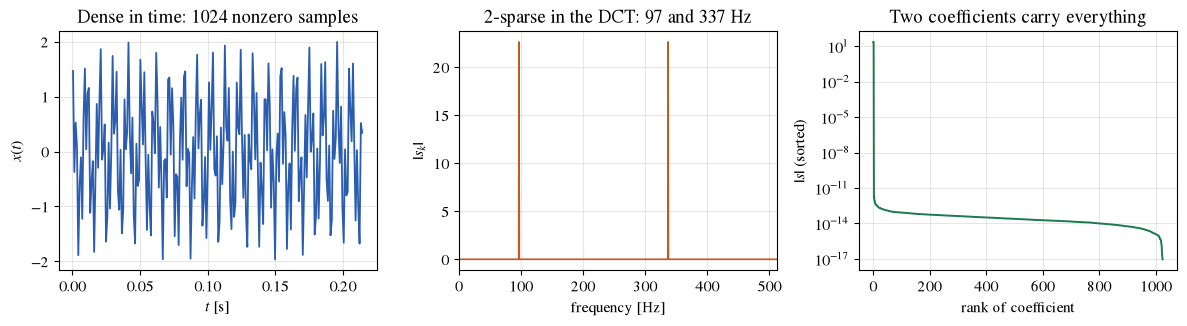

In [5]:
def plot_signal_sparse():
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
    ax[0].plot(t[:220], x1d[:220], color='C0', lw=1.3)
    ax[0].set(xlabel='$t$ [s]', ylabel='$x(t)$',
              title=f'Dense in time: {N1D} nonzero samples')
    ax[1].plot(np.arange(N1D)/(2*T), np.abs(s1d), color='C1', lw=1.2)
    ax[1].set(xlabel='frequency [Hz]', ylabel='$|s_k|$',
              title=f'2-sparse in the DCT: {F1:.0f} and {F2:.0f} Hz')
    ax[1].set_xlim(0, 512)
    ax[2].semilogy(np.arange(1, N1D+1), np.sort(np.abs(s1d))[::-1] + 1e-18,
                   color='C2', lw=1.4)
    ax[2].set(xlabel='rank of coefficient', ylabel='$|s|$ (sorted)',
              title='Two coefficients carry everything')
    plt.tight_layout()


save_dual(plot_signal_sparse, 'cs_signal_sparse', FIG)
plt.show()

**How to read this figure.** Left: the first 220 of the 1024 samples of
$x(t)$ against time $t$ in seconds. Middle: the DCT magnitude $|s_k|$ against
frequency in Hz, shown from 0 to 512 Hz. Right: all 1024 magnitudes sorted
from largest to smallest (rank on the horizontal axis), on a logarithmic
vertical axis.

**What it shows.** The waveform looks irregular and every one of its 1024
samples is nonzero. The spectrum has only two spikes, at 97 and 337 Hz, and
is zero elsewhere. In the sorted plot the first 2 values are large and the
next value drops by more than ten orders of magnitude, down to round-off
level. Sparsity is a property of the signal *in a basis*: the same vector
is fully dense in time and 2-sparse in the DCT.

The second figure does the same for the portrait and adds the compressed
reconstructions.

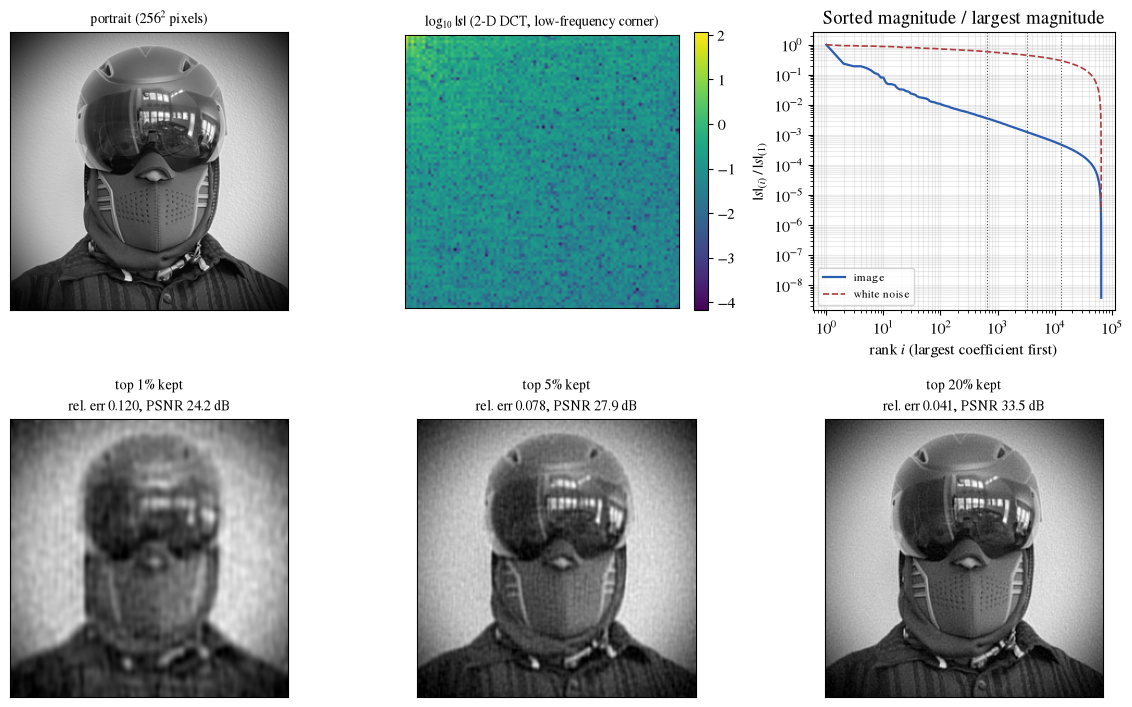

In [6]:
def plot_sparsity_image():
    fig, ax = plt.subplots(2, 3, figsize=(11.5, 7.2))
    ax[0, 0].imshow(img, cmap='gray', vmin=0, vmax=1)
    ax[0, 0].set_title('portrait ($256^2$ pixels)', fontsize=10)
    lo = np.log10(np.abs(S_img) + 1e-6)
    im = ax[0, 1].imshow(lo[:96, :96], cmap='viridis')
    ax[0, 1].set_title('$\\log_{10}|\\boldsymbol{s}|$ (2-D DCT, low-frequency corner)', fontsize=10)
    fig.colorbar(im, ax=ax[0, 1], fraction=0.046)
    ax[0, 2].loglog(np.arange(1, mag.size+1), mag/mag[0], color='C0', lw=1.6,
                    label='image')
    ax[0, 2].loglog(np.arange(1, mag.size+1), mag_noise/mag_noise[0], color='C3',
                    lw=1.2, ls='--', label='white noise')
    for f in FRACS:
        ax[0, 2].axvline(f*mag.size, color=muted(), lw=0.8, ls=':')
    ax[0, 2].set(xlabel='rank $i$ (largest coefficient first)',
                 ylabel='$|s|_{(i)}\\,/\\,|s|_{(1)}$',
                 title='Sorted magnitude / largest magnitude')
    ax[0, 2].legend(fontsize=8)
    ax[0, 2].grid(True, which='both', alpha=0.25)
    for j, f in enumerate(FRACS):
        kkept, relerr, p = stats[f]
        ax[1, j].imshow(recons[f], cmap='gray', vmin=0, vmax=1)
        ax[1, j].set_title(f'top {100*f:.0f}% kept\nrel. err {relerr:.3f}, PSNR {p:.1f} dB',
                           fontsize=10)
    for a in [ax[0, 0], ax[0, 1], ax[1, 0], ax[1, 1], ax[1, 2]]:
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
    plt.tight_layout()


save_dual(plot_sparsity_image, 'cs_sparsity_image', FIG)
plt.show()

**How to read this figure.** Top left: the $256\times256$ portrait. Top
middle: $\log_{10}|\boldsymbol{s}|$ for the $96\times96$ low-frequency corner of
the 2-D DCT (the top-left entry is the mean brightness; frequency grows to
the right and downward). Yellow means large coefficients, dark blue means
tiny ones; the colour bar gives the power of ten. Top right: take the
absolute value of every coefficient, sort them from largest to smallest,
$|s|_{(1)}\ge|s|_{(2)}\ge\dots$, and divide by the largest one. The
vertical axis is this ratio $|s|_{(i)}/|s|_{(1)}$ (1 for the biggest
coefficient, 0.01 for one a hundred times smaller), the horizontal axis
is the rank $i$, both logarithmic, for the image (solid blue) and for
white noise (dashed red). Dividing by the largest value puts both curves
on the same scale, so only their *shape* is compared. The dotted vertical lines
mark the 1%, 5% and 20% ranks (655, 3277 and 13107 coefficients). Bottom
row: the image rebuilt from only the top 1%, 5% and 20% of coefficients,
with the relative error and PSNR in each title.

**What it shows.** The large coefficients crowd into the top-left corner of
the DCT; most of the plane is small. In the decay plot the image curve
falls steadily (a power law) while the noise curve stays near 1 until the
very end, so noise has no small set of important coefficients. The
reconstructions follow: with 1% (rel. error 0.120, 24.2 dB) the face is
recognisable but blurred and blocky; with 5% (0.078, 27.9 dB) the details
return; with 20% (0.041, 33.5 dB) the result is close to the original. This
is exactly the JPEG bargain, measured on a real photograph.

## Summary

* The two-tone signal is fully dense in time (1024 of 1024 samples nonzero)
  and **exactly 2-sparse** in the DCT. Sparsity is a statement about a
  *basis*, never about a signal on its own.
* The portrait has $256^2 = 65\,536$ pixels, but its largest 1% of DCT
  coefficients already hold 98.558% of the energy. Keeping the top 20%
  reconstructs it to 0.0413 relative error (33.46 dB). That is the JPEG
  bargain, quantified on a real photograph.
* Compressibility shows up as a power-law collapse of the sorted
  magnitudes. White noise, by contrast, has a flat spectrum and is
  incompressible. No sparsifying basis, no compressed sensing.
* **The scandal**: this pipeline measures all $n$ values and then throws
  most of them away. Compressed sensing moves the compression *before* the
  acquisition, which is the subject of the next notebooks, starting with
  `cs_illustrations`.

## Try this

1. Set `F1 = 97.3` (a frequency that is not on the DCT grid), and comment
   out the two asserts in that cell so it runs. Expect `nnz` to jump from 2
   to essentially all coefficients, and the sorted-magnitude curve to decay
   gradually instead of dropping off a cliff: the signal is now only
   compressible, not sparse.
2. Set `F2 = 450.0`. Expect the signal to stay exactly 2-sparse, with the
   second spike moving to $k=900$, while the Nyquist rate rises to 900
   samples/s. The number of samples classical theory asks for grows with
   the highest frequency; the number of nonzero coefficients does not.
3. Replace the portrait by noise: insert `img = rng.standard_normal((NIMG, NIMG))`
   just before `S_img = dctn(...)`. Expect the relative errors at 1%, 5%
   and 20% to stay large (most of the energy is spread over the discarded
   coefficients) and the asserts in "Checking the claims" to fail, which is
   the point.
4. Change `NIMG` to 128. Expect slightly larger errors and slightly less
   energy in the top 1%: a smaller image has fewer coefficients to spread
   its smooth regions over, so it is a little less compressible.